# CM laser big scan (2026-10-19): space charge first, then the static model

**Scan** (`make_bigscan.py`, `make_bigscan_maps.py`: 72 Rossegger + 2780 laser jobs), keff = b × I_side (all-module
median GEM current of the side), P/T-corrected CM field, residuals vs CM truth and vs field off for every configuration:

| | what | where |
|---|---|---|
| A | 41 maps × b 0.45–0.90 (step 0.025) × 17 blocks, z −40, tilt 0.16 / 0.85 | space charge |
| maps | α 1.6 / 1.8 / 2.0 × inner kink r0 22.75 / 25 / 27.5 cm × width 2 / 4 cm × outer fall-off off / 72 cm; α 1.25 / 1.6 / 2.0 production; default CDB map; mt3 | |
| B | 10 TPC geometries (z −60…−10; rot_x 0 / 0.32; rot_y 0.65 / 1.05) × 17 blocks × static variants (IFC ±60 V per side, frame 0 / −360) + α 1.6 / 2.0 at b 0.55–0.75; no beam 75073 / 83319 and field off 78242 | static model |

**Order:**
- **A, space charge only.** Beam − no beam: the static distortion, the truth pattern and field off cancel. Pin the
  map and b.
- **B, the distributions at that keff.** 1D projections, per ring, per φ, per sector and maps.
- **C, the static model.** No beam vs field off (no space charge) and the tilt.

All figures show two panels (South | North unless noted). Δφ = RΔφ/R (a flat Δφ is a rotation, which is free); the
sagitta is from the Δφ slope (5290 µm per mrad/cm).

In [1]:
%matplotlib inline
import numpy as np, matplotlib.pyplot as plt
import bsnb as b, bsplots as bp, cmplots as c, v2plots as v
plt.rcParams['figure.dpi'] = 80
def show(*figs):
    for f in figs:
        display(f)
    plt.close('all')
D = bp.data()

## A. Space charge only: beam − no beam
### A1. Which map?
χ² of a flat Δφ(R) (rotation free) over all blocks and both sides. The 795xx runs use one b; 80892 and 81558 each use
their own b. Maps are ranked by χ² 795xx + high lumi.

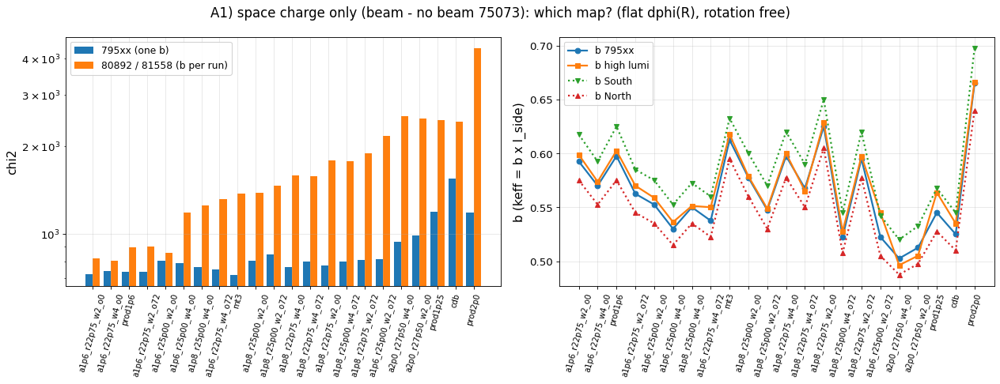

map                     b 795xx   chi2  b high   chi2 one b all  b South  b North   N/S  sag lo  sag hi
a1p6_r22p75_w2_o0         0.593    725   0.599    819      1669    0.618    0.575  0.93      +2     -48
a1p6_r22p75_w4_o0         0.570    743   0.574    804      1659    0.593    0.553  0.93      +6     -22
prod1p6                   0.598    737   0.603    898      1744    0.625    0.575  0.92      +4     -42
a1p6_r22p75_w2_o72        0.563    737   0.570    903      1735    0.585    0.545  0.93      -0     -13
a1p6_r25p00_w2_o0         0.553    808   0.559    860      1778    0.575    0.535  0.93      +7      +0
a1p6_r25p00_w4_o0         0.530    793   0.536   1179      2112    0.553    0.515  0.93      +7     +42
a1p8_r25p00_w4_o0         0.550    768   0.551   1247      2107    0.573    0.535  0.93     -21     -79
a1p6_r22p75_w4_o72        0.538    751   0.550   1317      2253    0.560    0.523  0.93      -0     +55
mt3                       0.613    722   0.618   1372      2214 

In [2]:
fig, rows = b.a_ranking(); show(fig)
print(f"{'map':22s} {'b 795xx':>8s} {'chi2':>6s} {'b high':>7s} {'chi2':>6s} {'one b all':>9s} {'b South':>8s} {'b North':>8s} {'N/S':>5s} {'sag lo':>7s} {'sag hi':>7s}")
for r in rows[:15] + [x for x in rows[15:] if x['map'] in ('prod2p0', 'cdb', 'prod1p25', 'mt3')]:
    print(f"{r['map']:22s} {r['b_low']:8.3f} {r['chi2_low']:6.0f} {r['b_high']:7.3f} {r['chi2_high']:6.0f} {r['chi2_all_oneb']:9.0f} "
          f"{r['b_S']:8.3f} {r['b_N']:8.3f} {r['b_N']/r['b_S']:5.2f} {r['sag_low']:+7.0f} {r['sag_high']:+7.0f}")

The same ranking with the other no-beam run (83319, after the IFC change and after the North change):

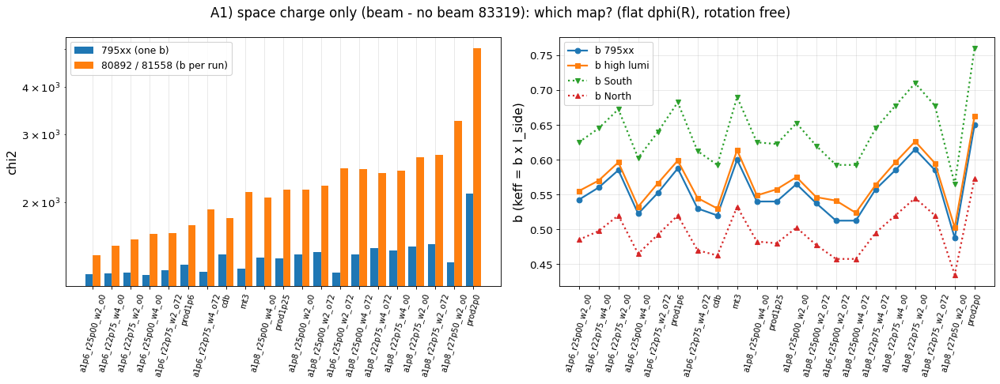

a1p6_r25p00_w2_o0      b 0.543 / 0.555  chi2 1302 / 1458  N/S 0.78
a1p6_r22p75_w4_o0      b 0.560 / 0.570  chi2 1309 / 1541  N/S 0.77
a1p6_r22p75_w2_o0      b 0.585 / 0.596  chi2 1314 / 1598  N/S 0.77
a1p6_r25p00_w4_o0      b 0.523 / 0.533  chi2 1297 / 1654  N/S 0.77
a1p6_r22p75_w2_o72     b 0.553 / 0.566  chi2 1329 / 1660  N/S 0.77
prod1p6                b 0.588 / 0.599  chi2 1377 / 1747  N/S 0.76
a1p6_r22p75_w4_o72     b 0.530 / 0.545  chi2 1319 / 1917  N/S 0.77
cdb                    b 0.520 / 0.530  chi2 1463 / 1822  N/S 0.78


In [3]:
fig, rows83 = b.a_ranking(nb=83319); show(fig)
for r in rows83[:8]: print(f"{r['map']:22s} b {r['b_low']:.3f} / {r['b_high']:.3f}  chi2 {r['chi2_low']:.0f} / {r['chi2_high']:.0f}  N/S {r['b_N']/r['b_S']:.2f}")

### A2. Radial profile parameters, keff linearity, North / South

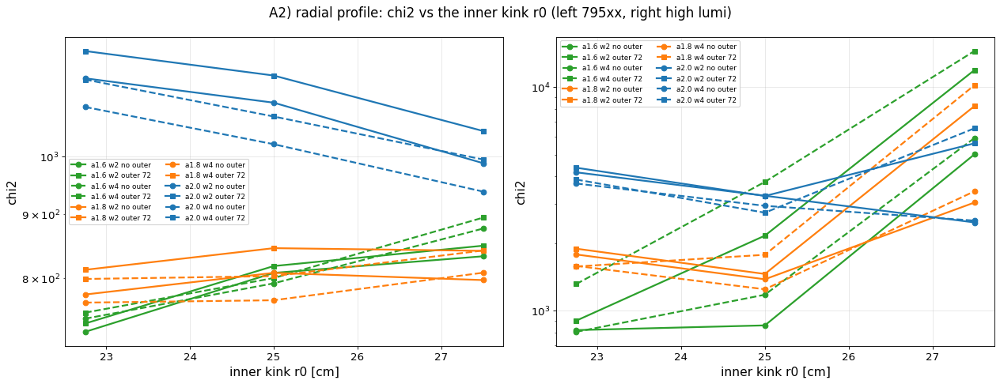

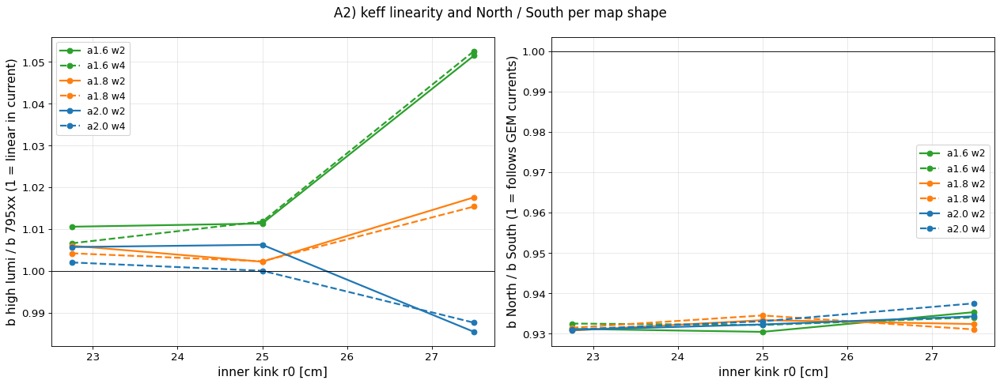

In [4]:
show(*b.a_params())

### A3. χ² vs b

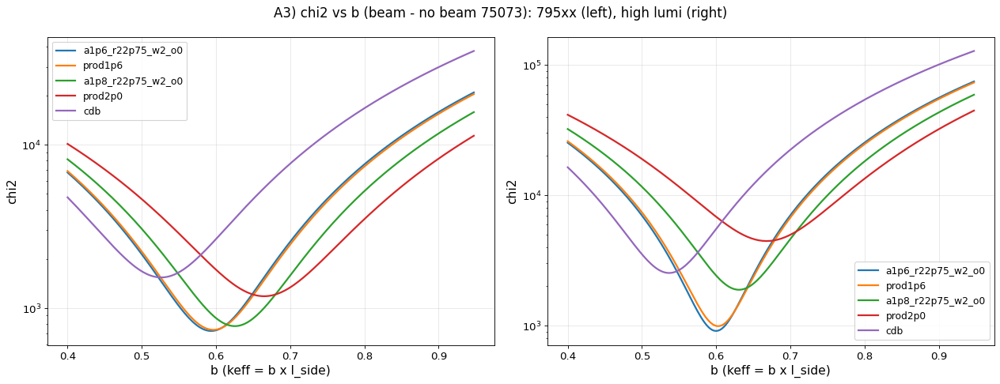

In [5]:
show(b.a_chi2_curves())

### A4. Δφ(R), RΔφ(R) per run at the best b: best map, α 2.0, default CDB map

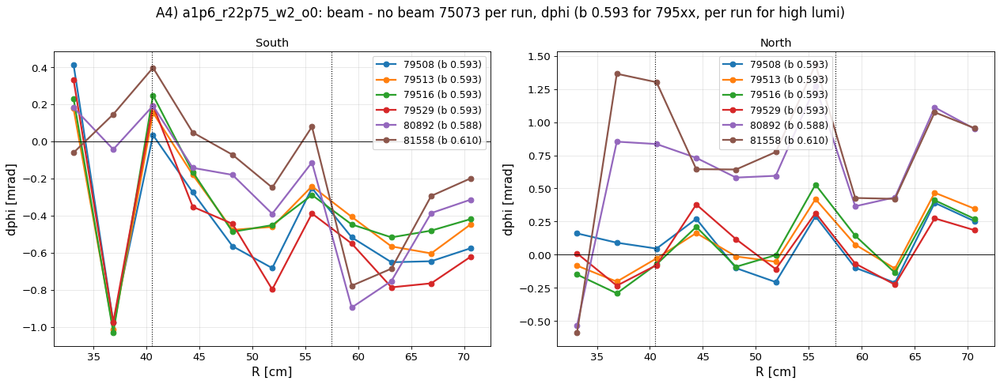

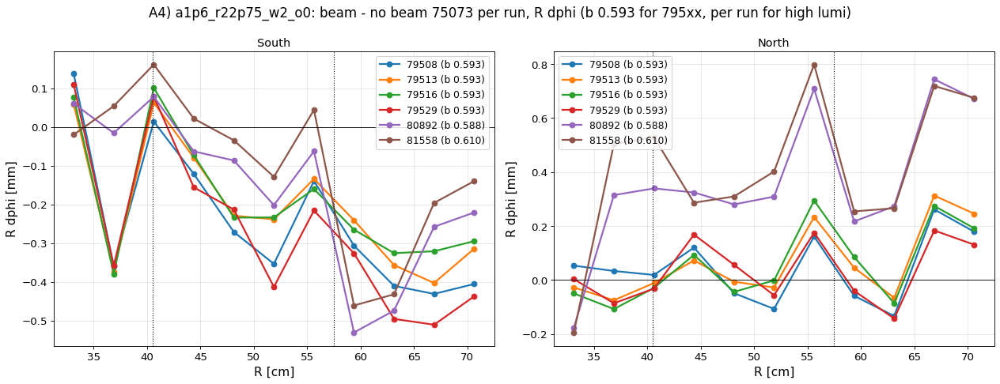

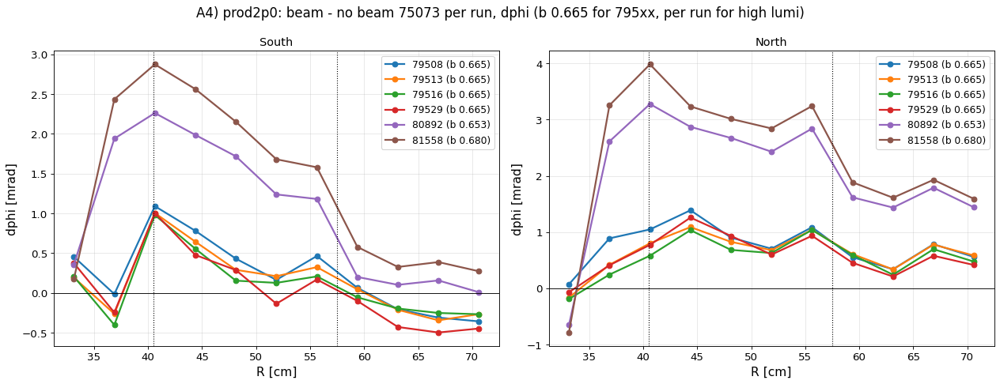

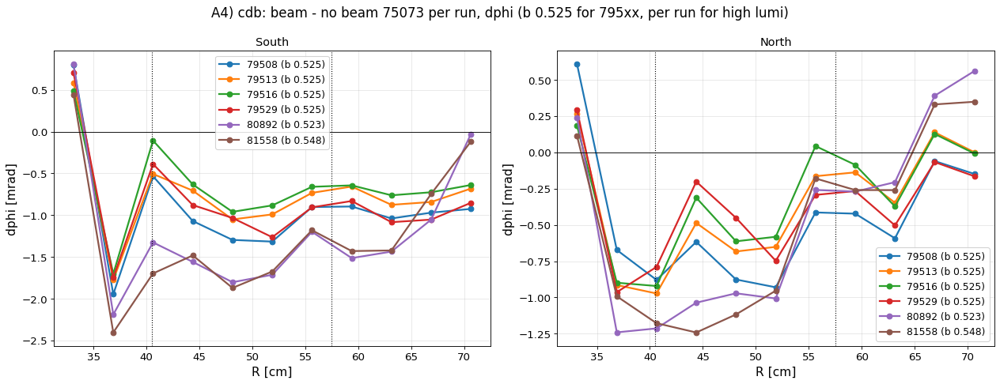

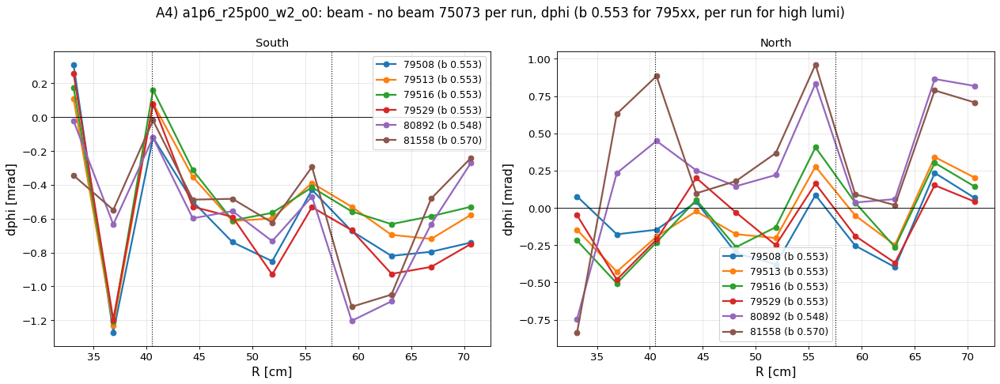

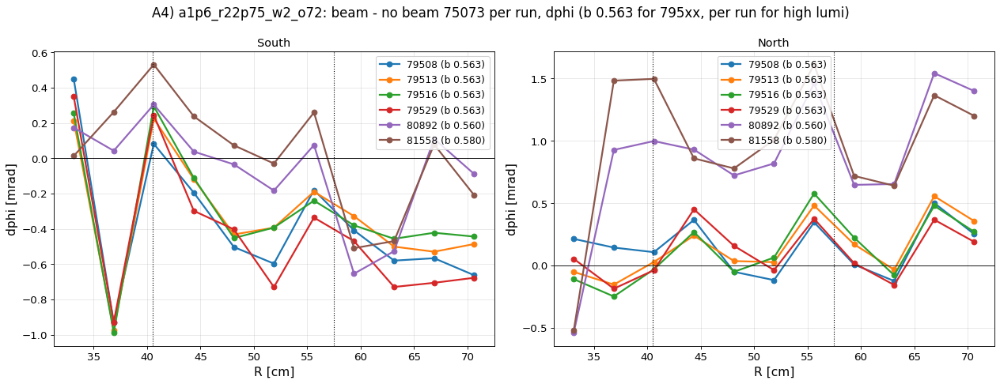

In [6]:
show(b.a_profiles(b.BEST, q=5), b.a_profiles(b.BEST, q=4))
show(b.a_profiles('prod2p0', q=5), b.a_profiles('cdb', q=5), b.a_profiles('a1p6_r25p00_w2_o0', q=5), b.a_profiles('a1p6_r22p75_w2_o72', q=5))

### A5. keff vs GEM current per side; A6. sector sagitta (gain structure)

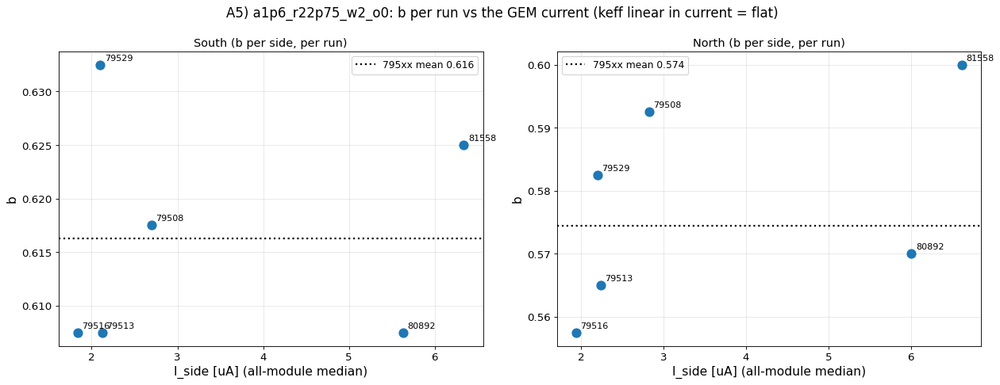

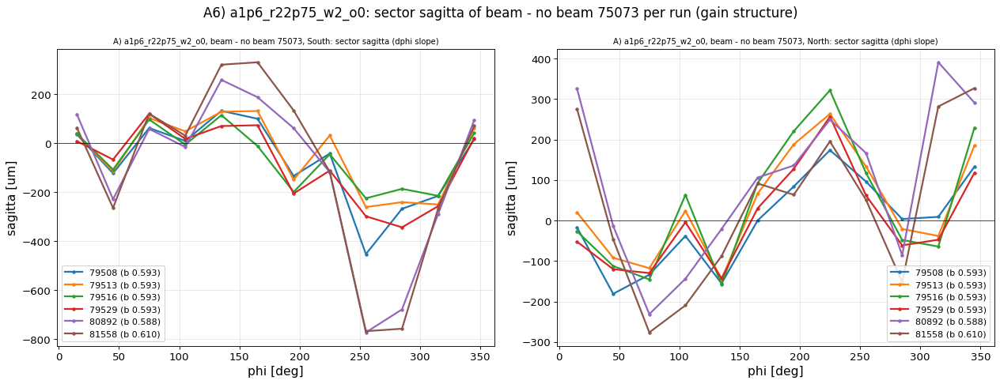

In [7]:
show(b.a_keff_runs(), b.a_sectors())

## B. Distributions at the space-charge keff
Per cluster, 795xx unless noted. **sc16** = α 1.6 at the space-charge-only b (the same family as the best map of A1).
Compared with: no correction, static only, α 2.0 at its space-charge b, the default CDB map at the CDB keff, and α 2.0 at
the laser-absolute b.
### B1. 1D projections (RΔφ, Δφ, dR)

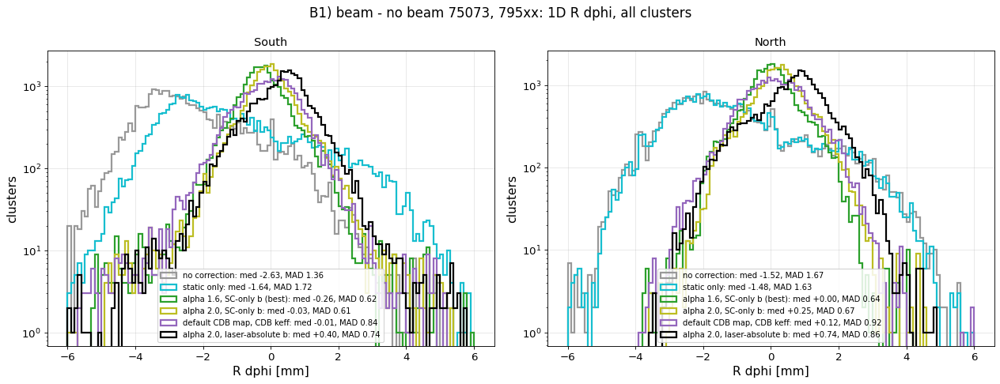

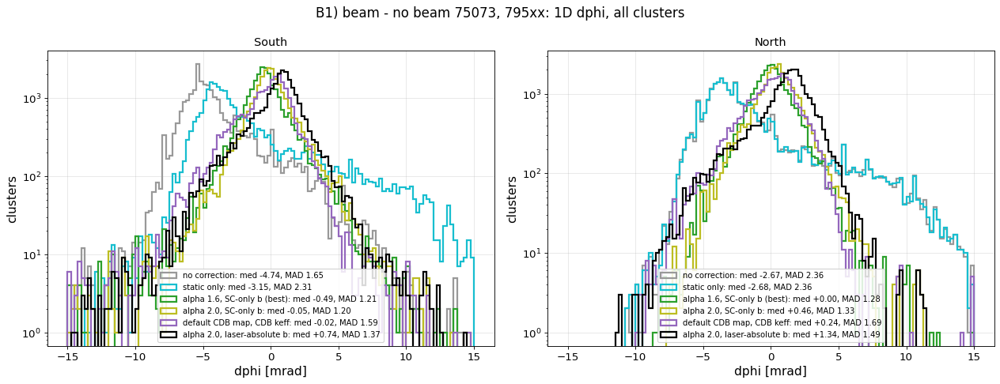

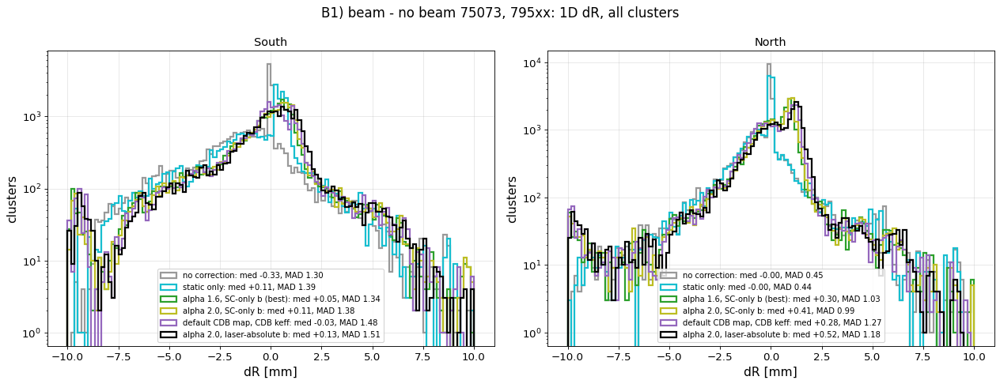

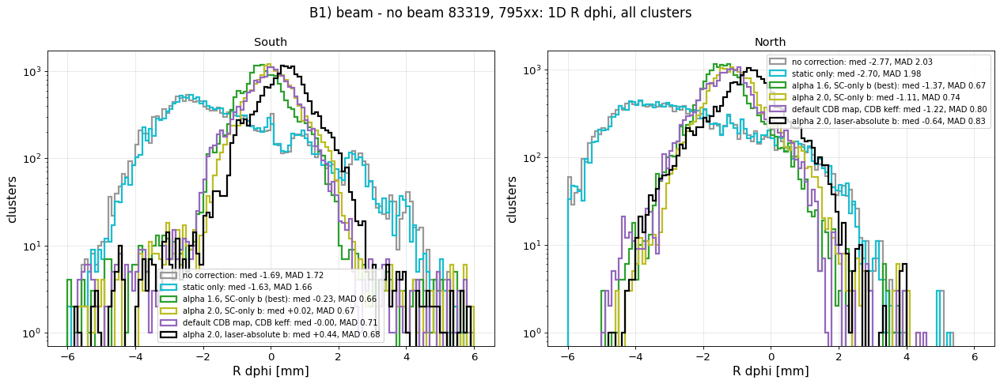

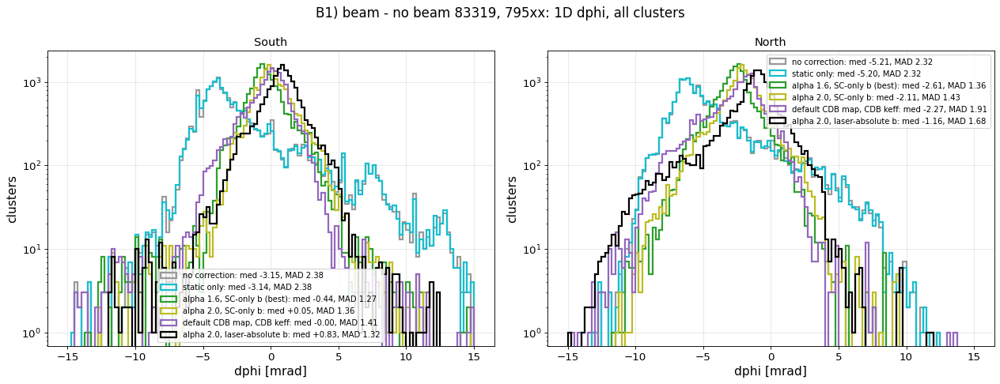

...

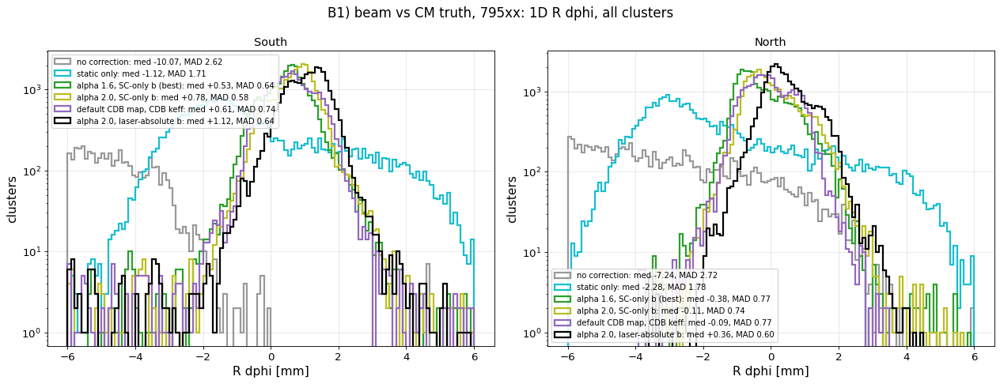

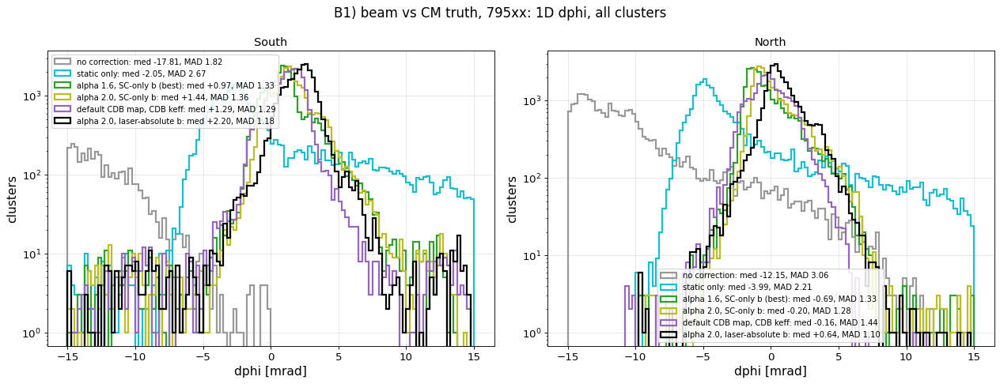

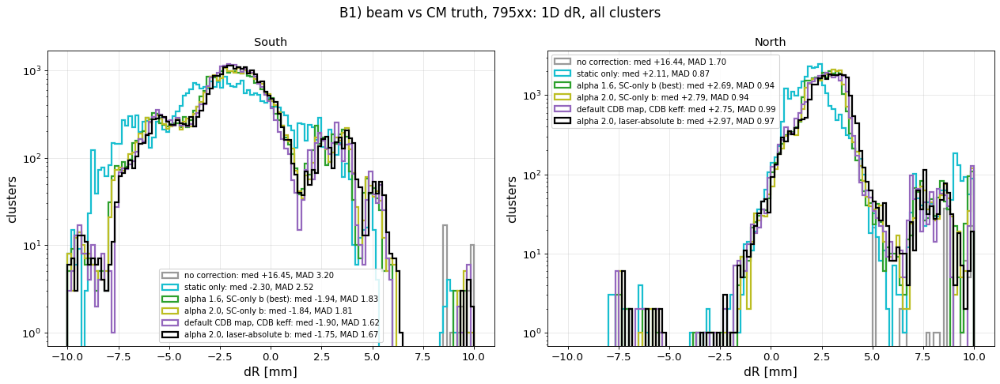

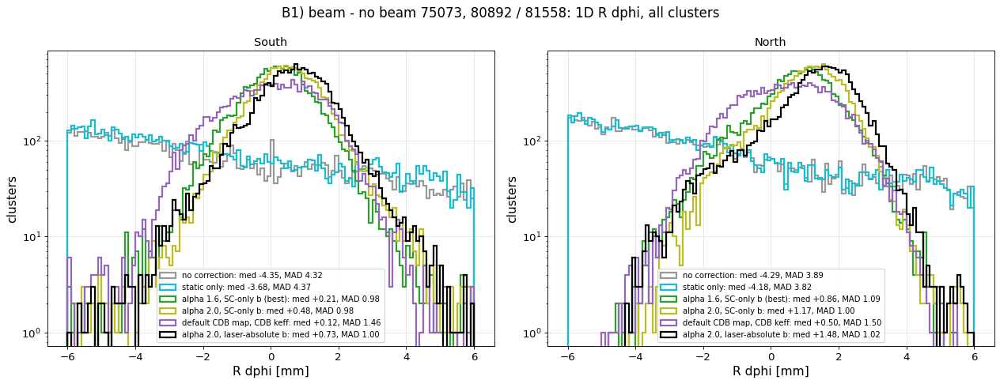

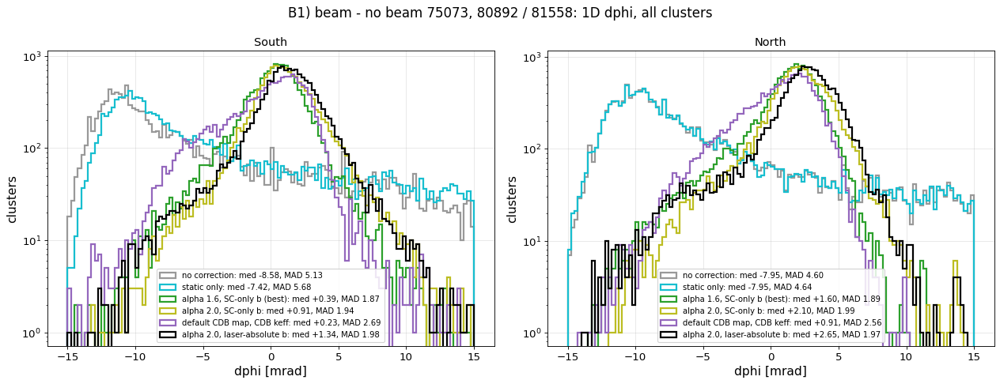

In [8]:
for cmp in ('NB75', 'NB83', 'OFF', 'T'):
    show(b.b_hist(cmp, 4), b.b_hist(cmp, 5), b.b_hist(cmp, 3))
show(b.b_hist('NB75', 4, lumi='high'), b.b_hist('NB75', 5, lumi='high'))

### B2. Per ring (layer): median and width

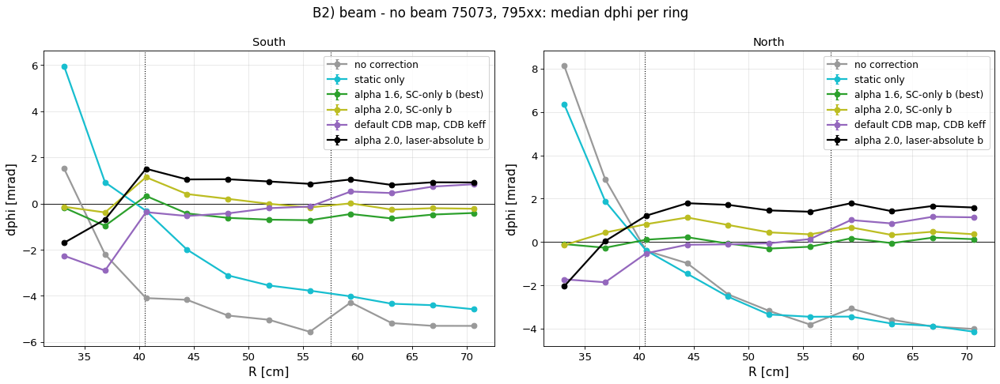

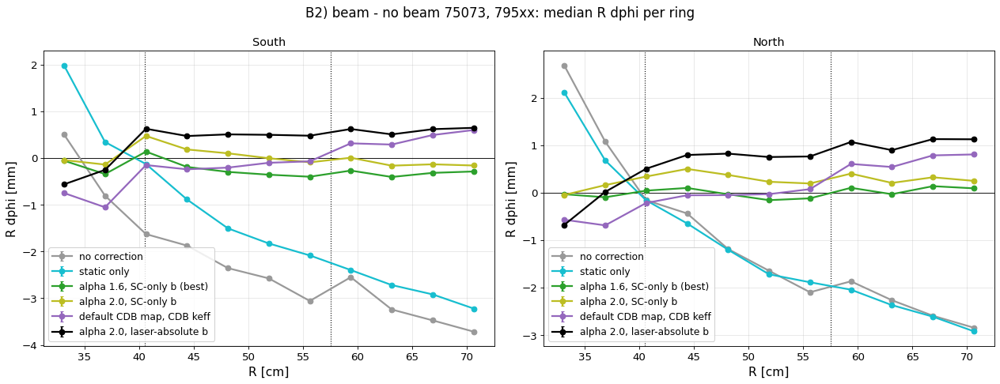

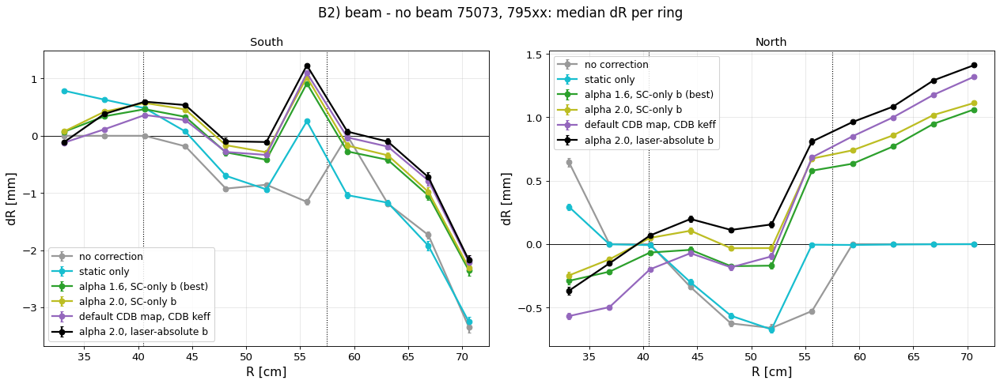

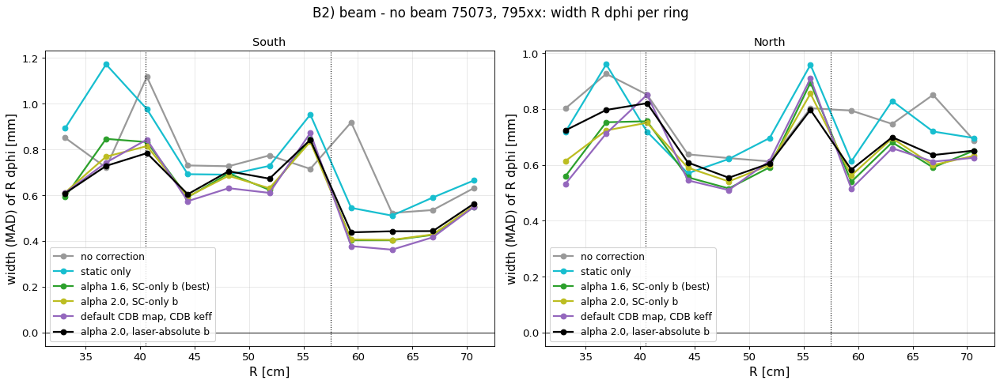

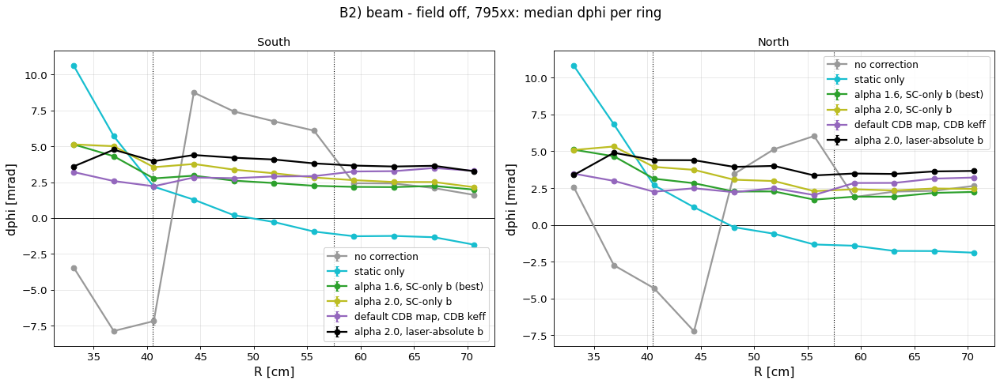

...

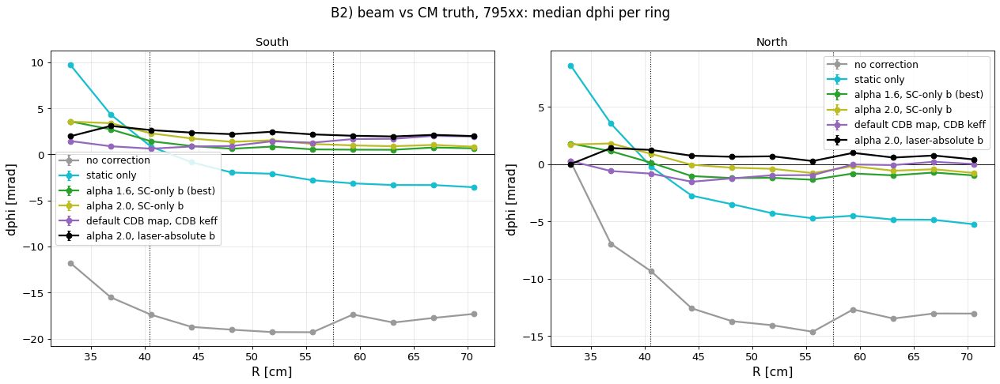

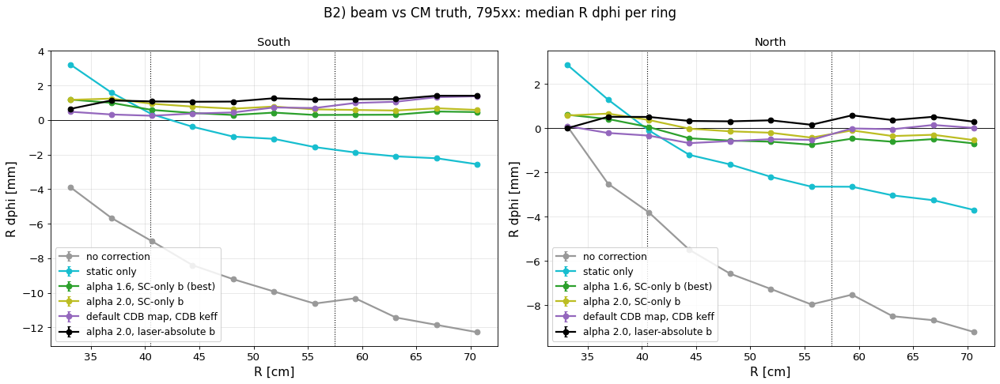

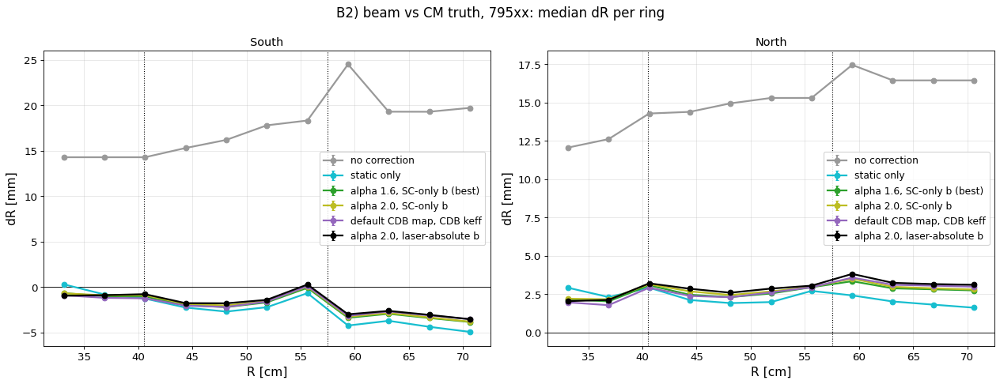

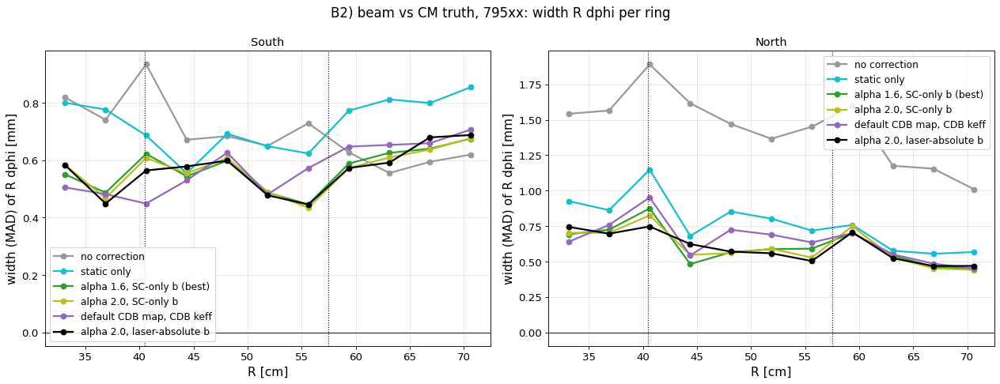

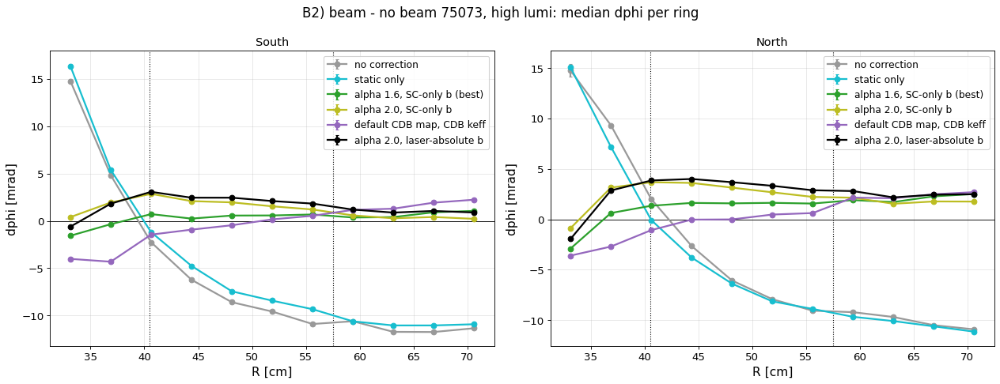

In [9]:
for cmp in ('NB75', 'OFF', 'T'):
    show(b.b_vs_r(cmp, 5), b.b_vs_r(cmp, 4), b.b_vs_r(cmp, 3), b.b_vs_r(cmp, 4, what='width'))
show(b.b_vs_r('NB75', 5, lumi='high'))

### B3. Versus φ: per module ring, and per configuration

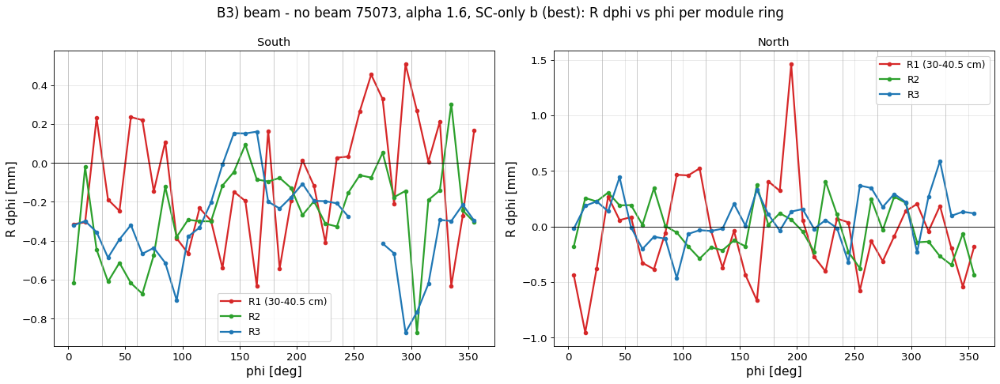

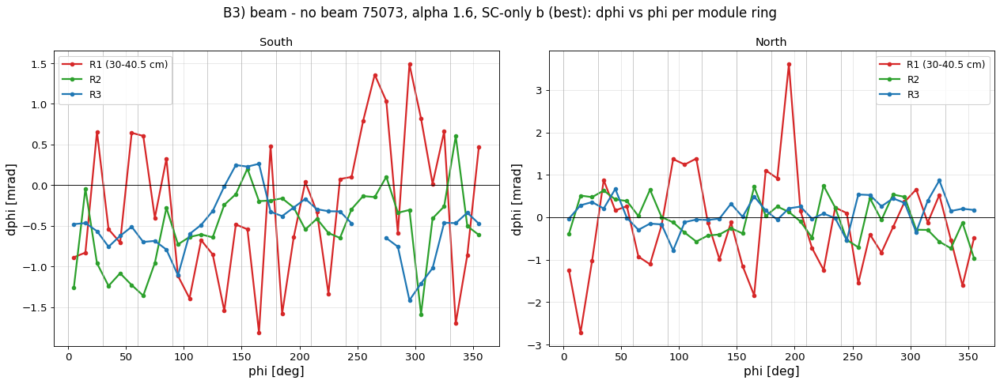

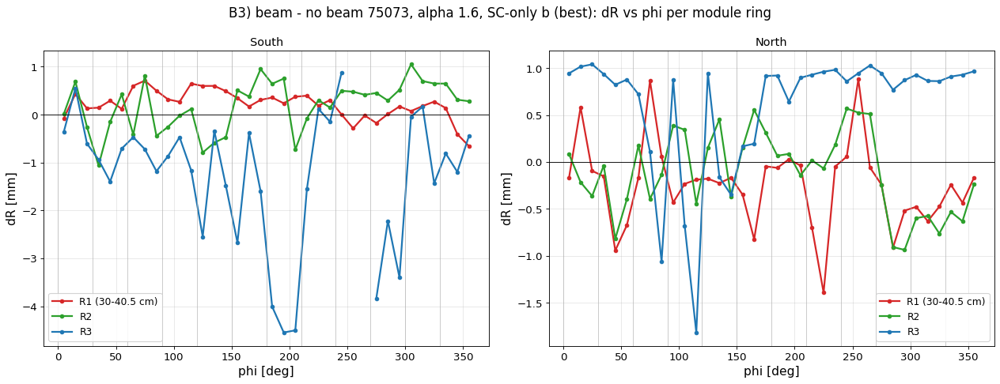

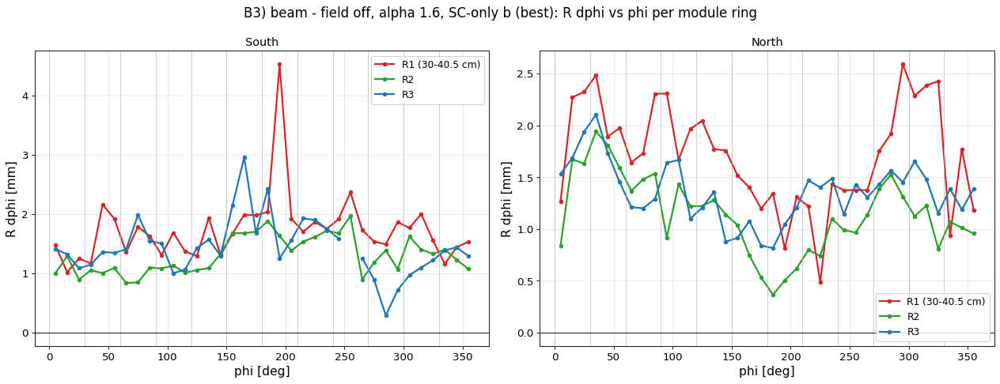

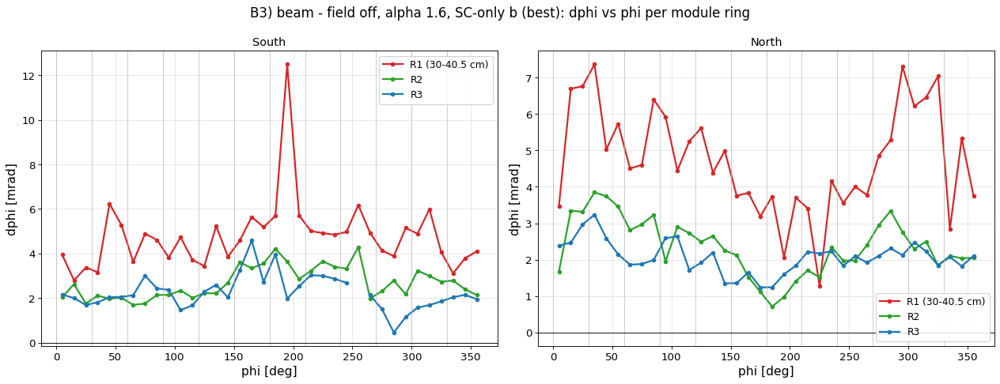

...

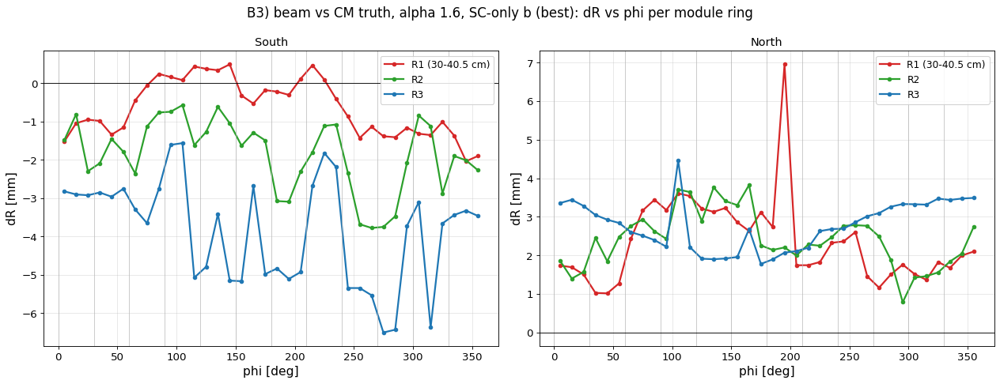

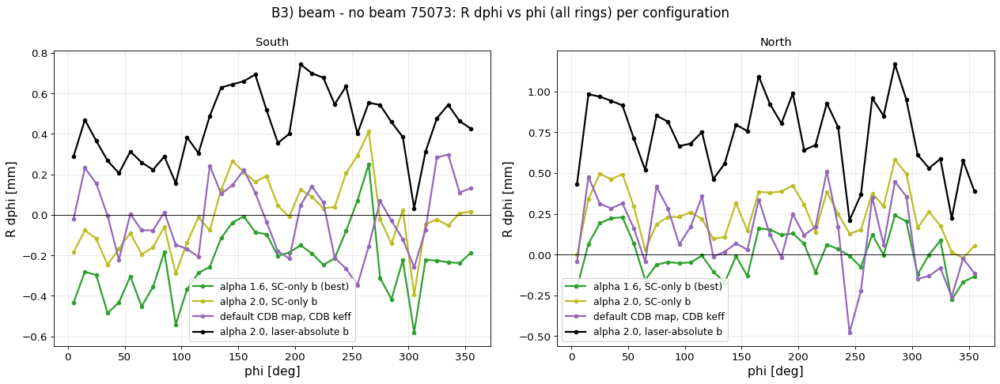

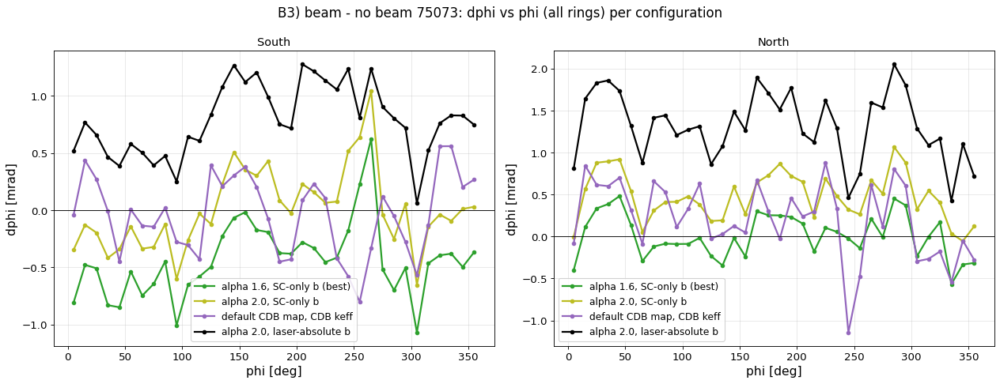

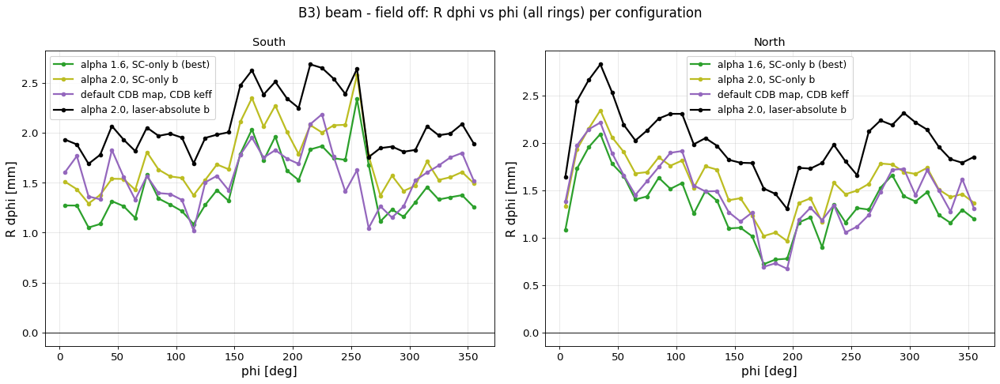

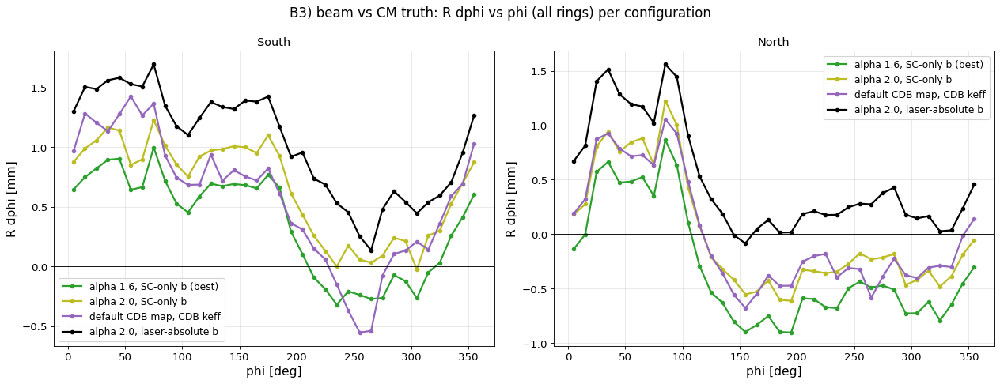

In [10]:
for cmp in ('NB75', 'OFF', 'T'):
    show(b.b_vs_phi(cmp, 4), b.b_vs_phi(cmp, 5), b.b_vs_phi(cmp, 3))
show(b.b_phi_stages('NB75', 4), b.b_phi_stages('NB75', 5), b.b_phi_stages('OFF', 4), b.b_phi_stages('T', 4))

### B4. Sector sagitta per run

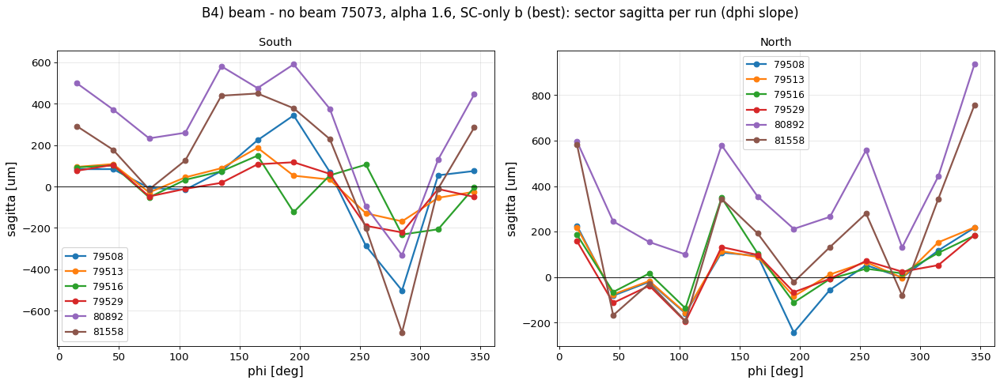

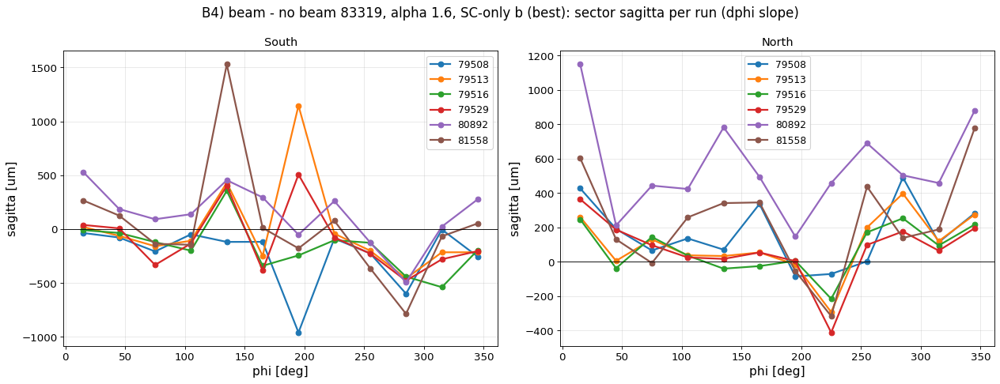

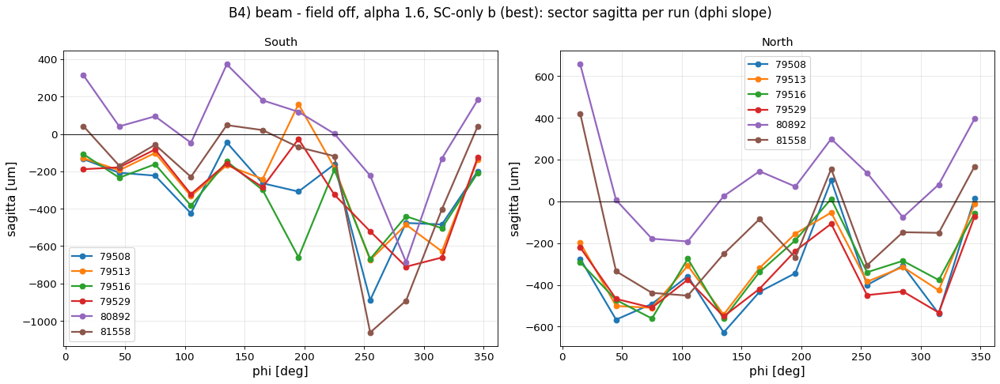

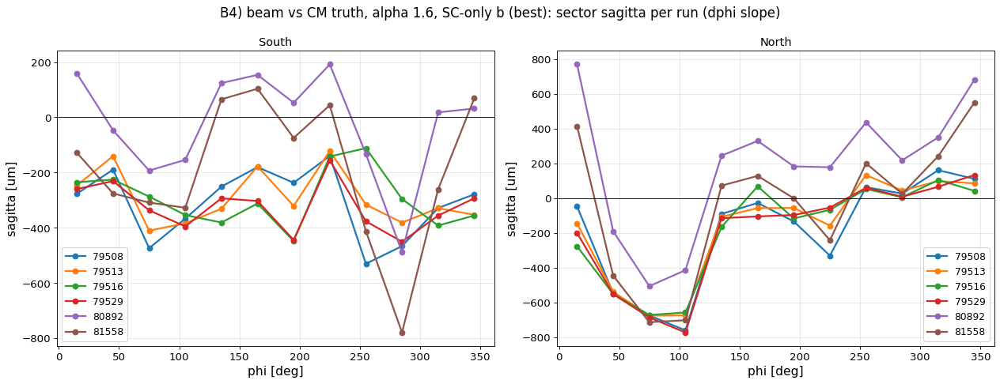

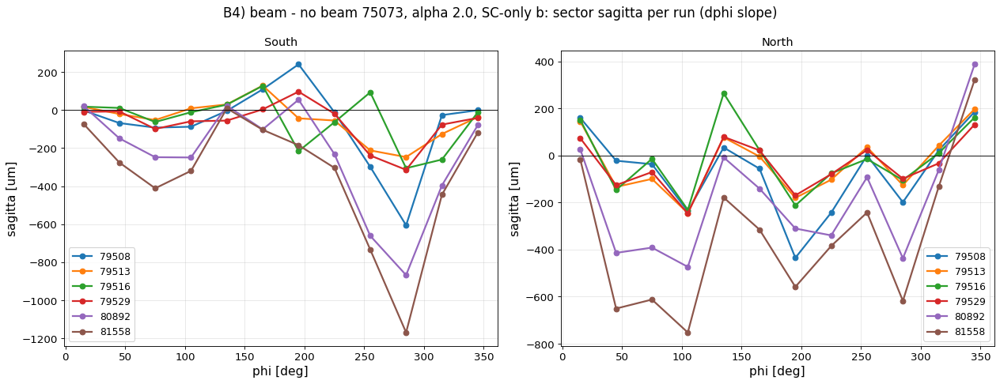

In [11]:
show(b.b_sector_sag('NB75'), b.b_sector_sag('NB83'), b.b_sector_sag('OFF'), b.b_sector_sag('T'), b.b_sector_sag('NB75', 'sc20'))

### B5. Maps vs (φ, R)

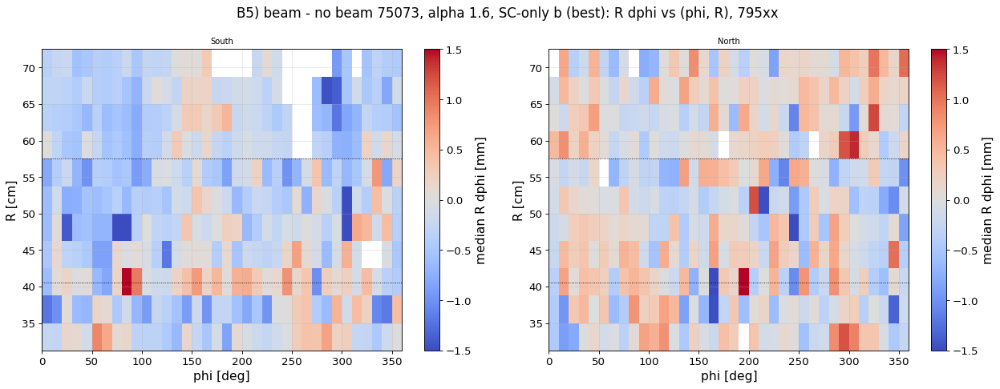

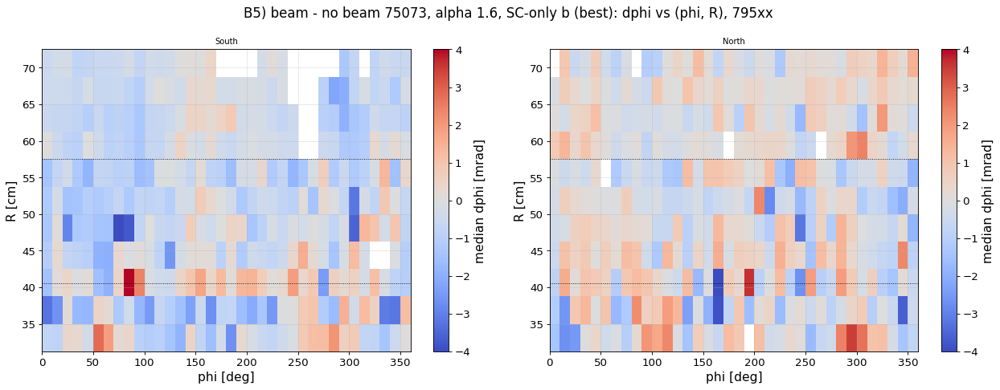

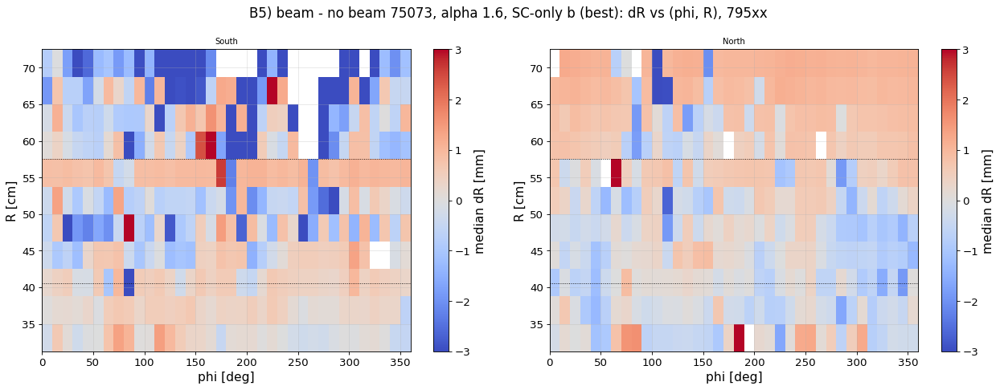

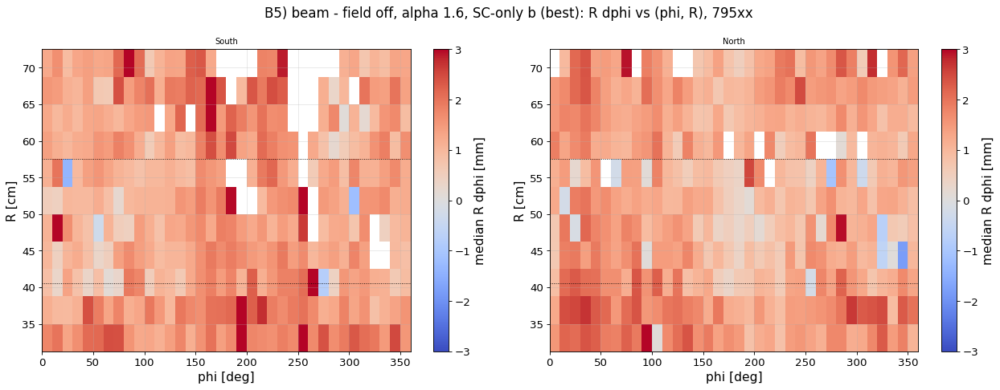

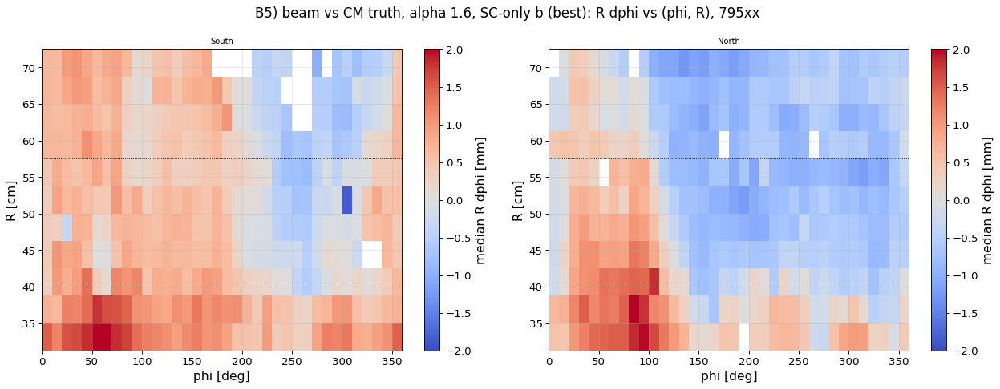

In [12]:
show(b.b_map('NB75', q=4), b.b_map('NB75', q=5, vlim=4), b.b_map('NB75', q=3, vlim=3), b.b_map('OFF', q=4, vlim=3), b.b_map('T', q=4, vlim=2))

### B6. 1D distribution per ring; B7. resolution (local width)

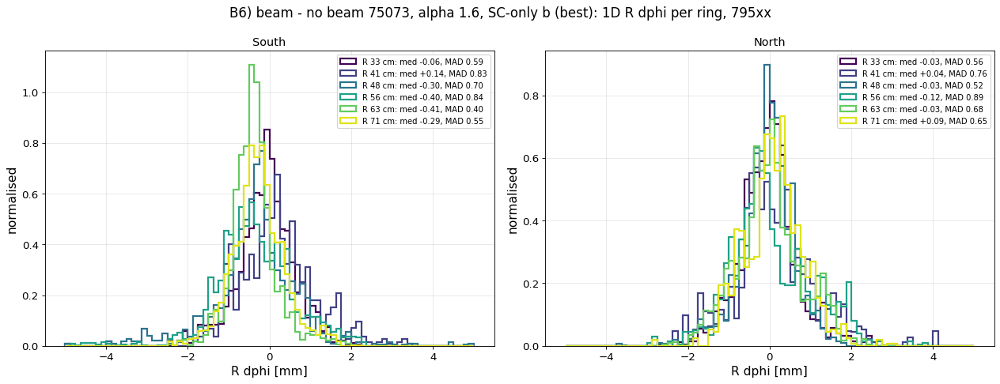

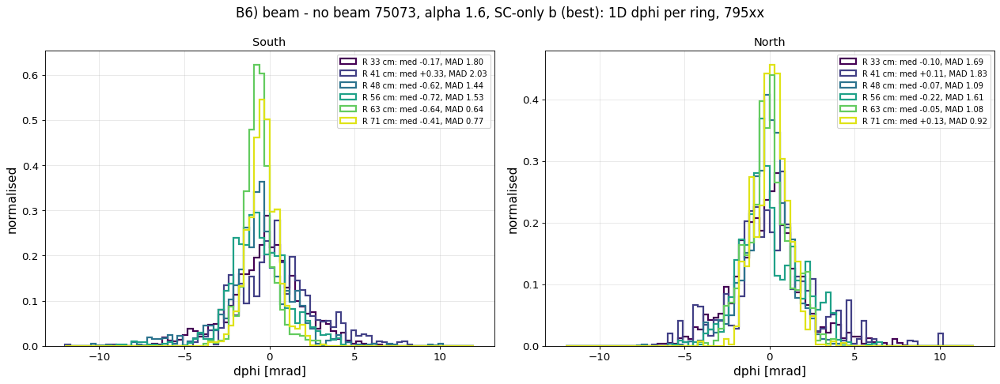

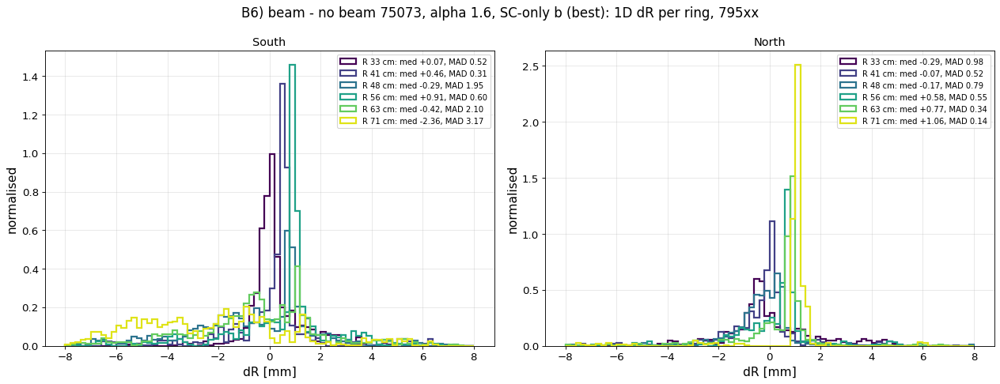

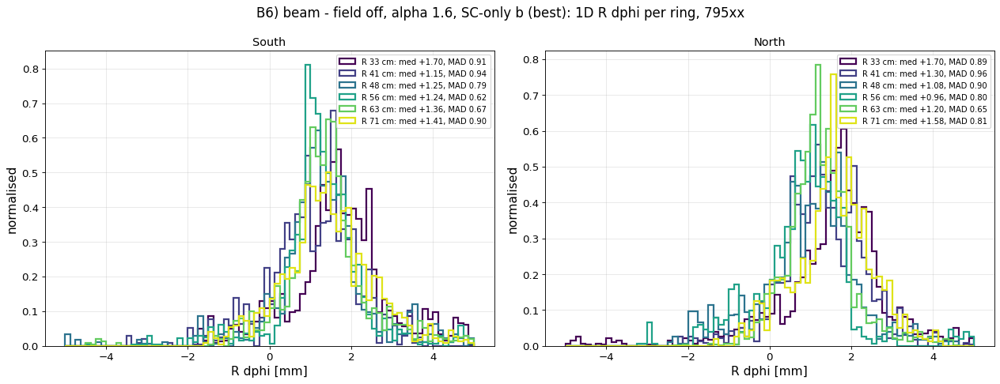

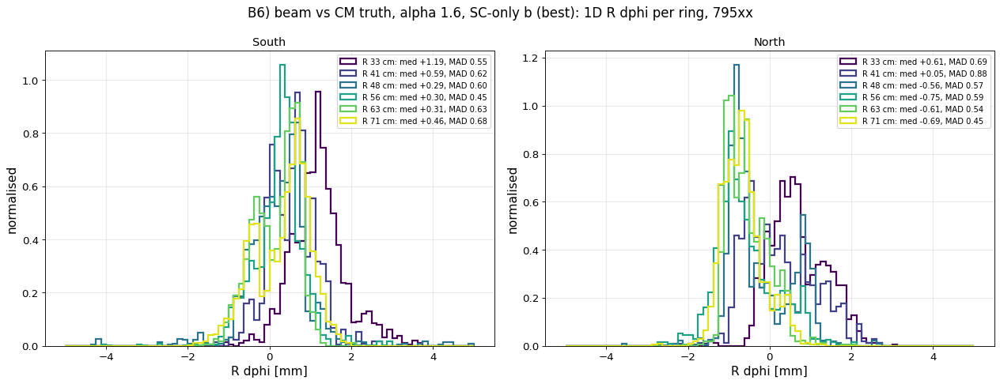

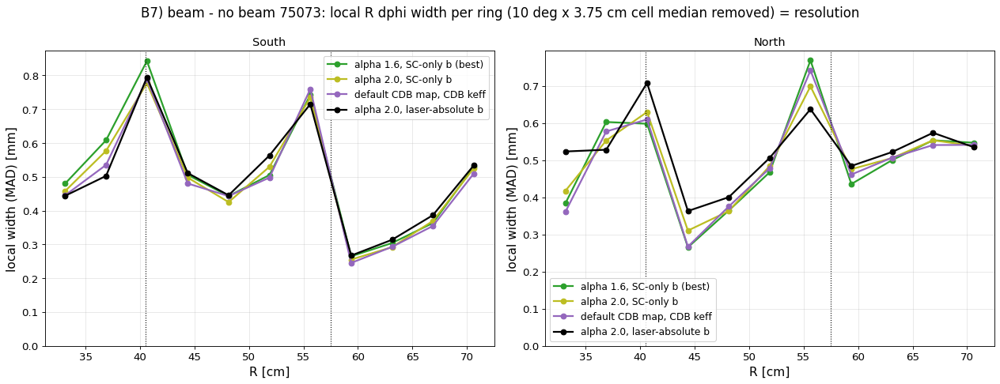

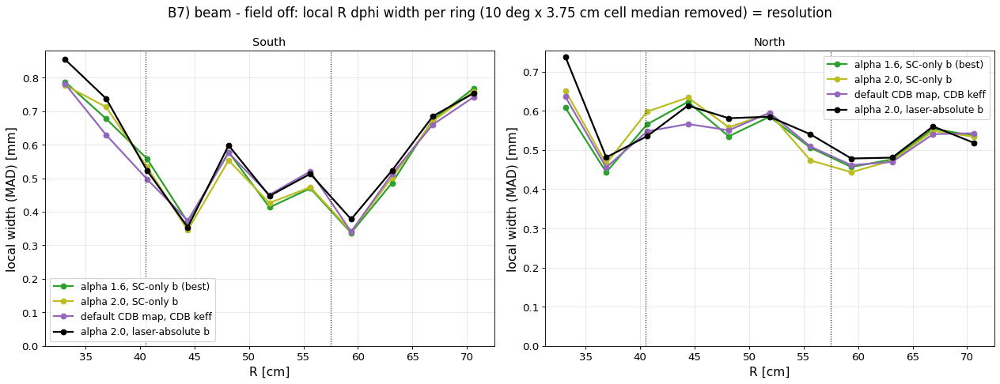

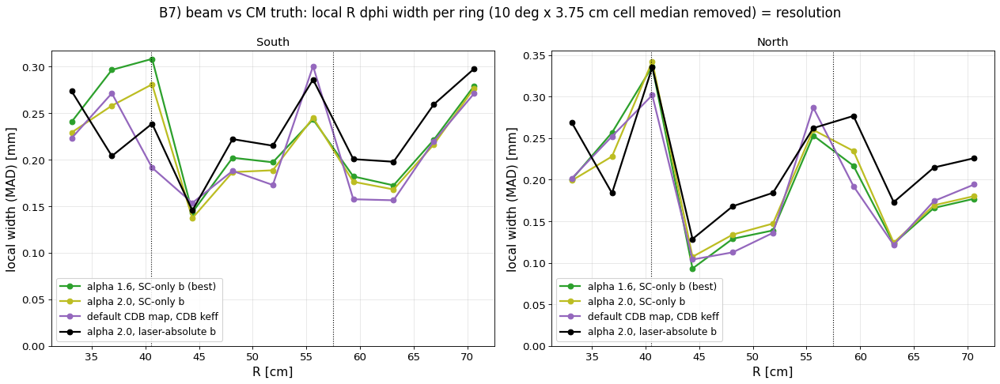

In [13]:
show(b.b_ring_1d('NB75', q=4), b.b_ring_1d('NB75', q=5), b.b_ring_1d('NB75', q=3), b.b_ring_1d('OFF', q=4), b.b_ring_1d('T', q=4))
show(b.b_local_width(), b.b_local_width(cmp='OFF'), b.b_local_width(cmp='T'))

## C. Static model
### C1/C2. No beam vs field off (no space charge): z, IFC, frame
The sagitta that the static model leaves with no beam at all. This is the piece that the laser-absolute keff absorbed
earlier. Below: the IFC voltage that would zero it, linear from the ±60 V variants.

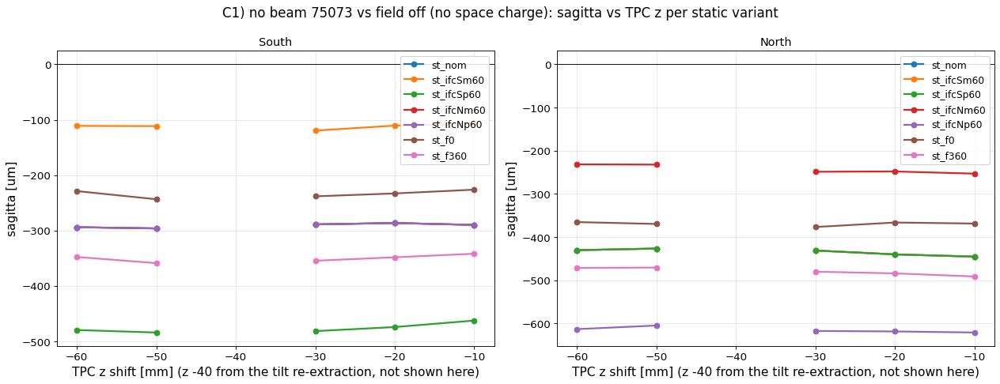

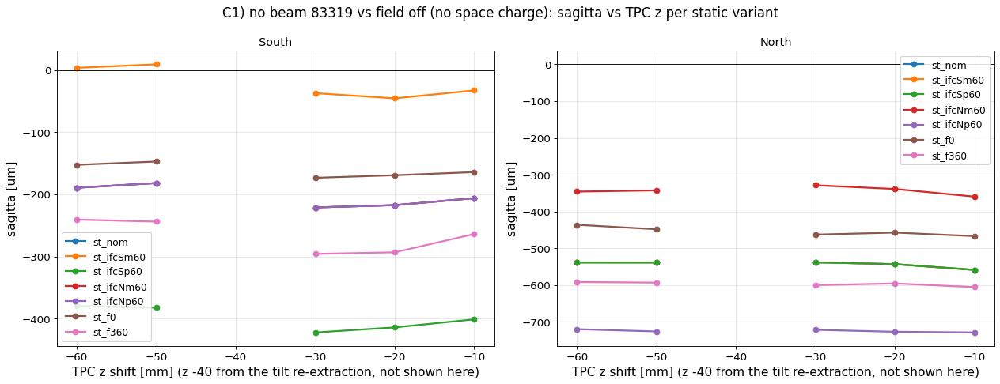

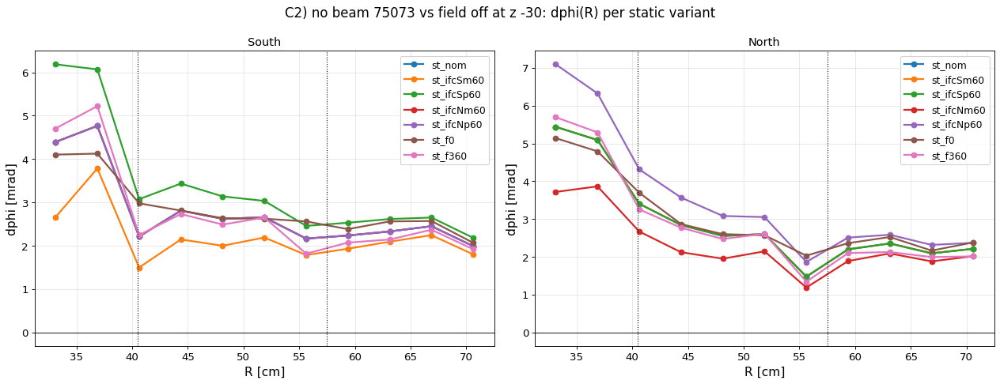

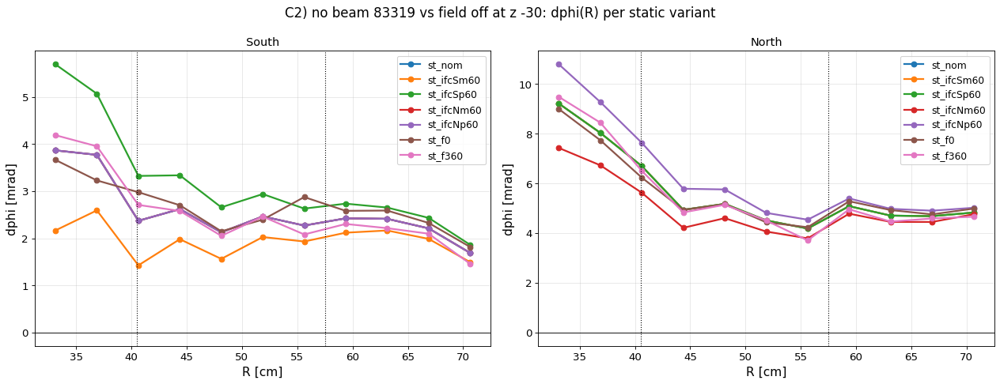

no beam 75073 z -60: South: sag  -294 um, -3.07 um/V -> IFC S offset   -96 V | North: sag  -430 um, -3.18 um/V -> IFC N offset  -135 V
no beam 75073 z -50: South: sag  -296 um, -3.10 um/V -> IFC S offset   -95 V | North: sag  -427 um, -3.11 um/V -> IFC N offset  -137 V
no beam 75073 z -30: South: sag  -289 um, -3.02 um/V -> IFC S offset   -96 V | North: sag  -431 um, -3.07 um/V -> IFC N offset  -140 V
no beam 75073 z -20: South: sag  -286 um, -3.03 um/V -> IFC S offset   -95 V | North: sag  -440 um, -3.09 um/V -> IFC N offset  -143 V
no beam 75073 z -10: South: sag  -290 um, -2.96 um/V -> IFC S offset   -98 V | North: sag  -445 um, -3.07 um/V -> IFC N offset  -145 V
no beam 83319 z -60: South: sag  -189 um, -3.19 um/V -> IFC S offset   -59 V | North: sag  -539 um, -3.12 um/V -> IFC N offset  -173 V
no beam 83319 z -50: South: sag  -182 um, -3.26 um/V -> IFC S offset   -56 V | North: sag  -539 um, -3.20 um/V -> IFC N offset  -169 V
no beam 83319 z -30: South: sag  -221 um, -3.21 um/V ->

In [14]:
show(b.c_static_z(75073), b.c_static_z(83319))
show(b.c_static_prof(75073), b.c_static_prof(83319))
R = c.RC[c.RING]
def sag_of(key):
    if key not in D.B: return np.nan
    d = 100 * D.B[key][0] / R; ok = np.isfinite(d)
    return np.polyfit(R[ok], d[ok], 1)[0] * v.SAG_PER_SLOPE
for run in (75073, 83319):
    for z in (-60, -50, -30, -20, -10):
        out = []
        for s, (m, p) in ((0, ('st_ifcSm60', 'st_ifcSp60')), (1, ('st_ifcNm60', 'st_ifcNp60'))):
            s0, sm, sp_ = (sag_of((0, run, 0, z, t, 0.0, s)) for t in ('st_nom', m, p))
            slope = (sp_ - sm) / 120
            out.append(f"{c.SIDES[s]}: sag {s0:+5.0f} um, {slope:+.2f} um/V -> IFC {'S' if s == 0 else 'N'} offset {-s0/slope:+5.0f} V")
        print(f"no beam {run} z {z:+d}: " + " | ".join(out))

### C3. Beam (α 1.6 / 2.0 at b 0.6) vs field off and vs truth: z dependence

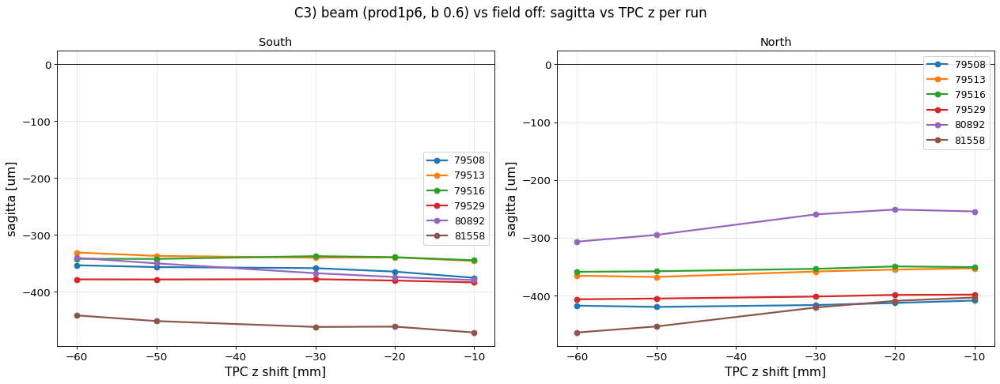

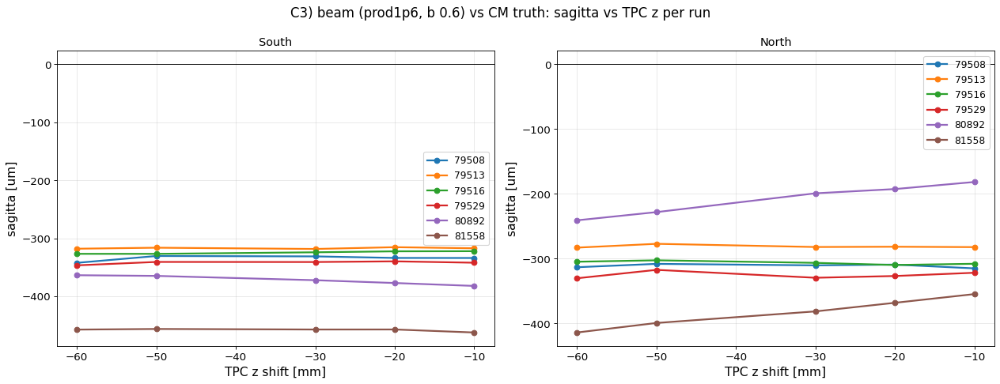

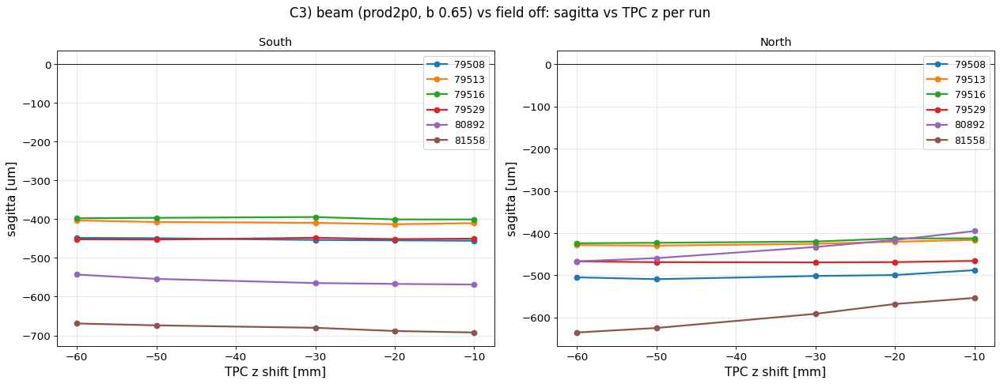

In [21]:
show(b.c_beam_z('prod1p6', 0.6, ref=0), b.c_beam_z('prod1p6', 0.6, ref=1), b.c_beam_z('prod2p0', 0.65, ref=0))

### C4. TPC tilt (z −40): first harmonic of RΔφ(φ) and sagitta per geometry

/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/bsnb.py:357: RuntimeWarning: Mean of empty slice
  PS = np.nanmean(T['PS'][sel], axis=0)          # [12, 11]
/home/yoren/yumvd.Yandex.Disk/Yura/sPHENIX/tracking/cm/laser_data/presentation/bsnb.py:357: RuntimeWarning: Mean of empty slice
  PS = np.nanmean(T['PS'][sel], axis=0)          # [12, 11]


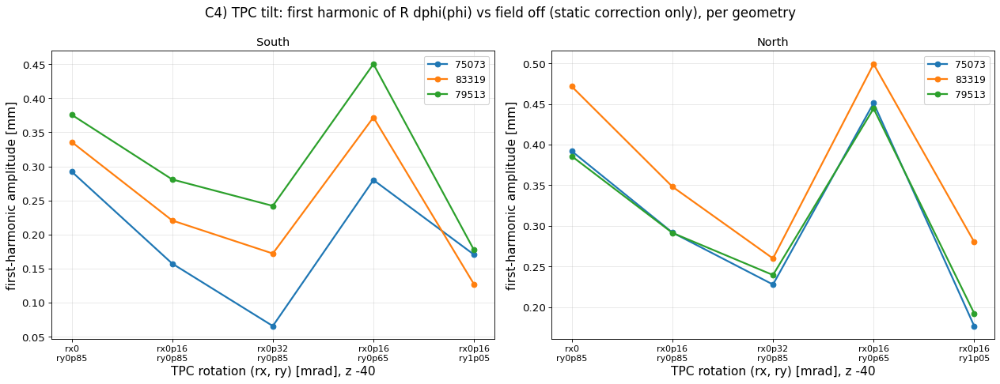

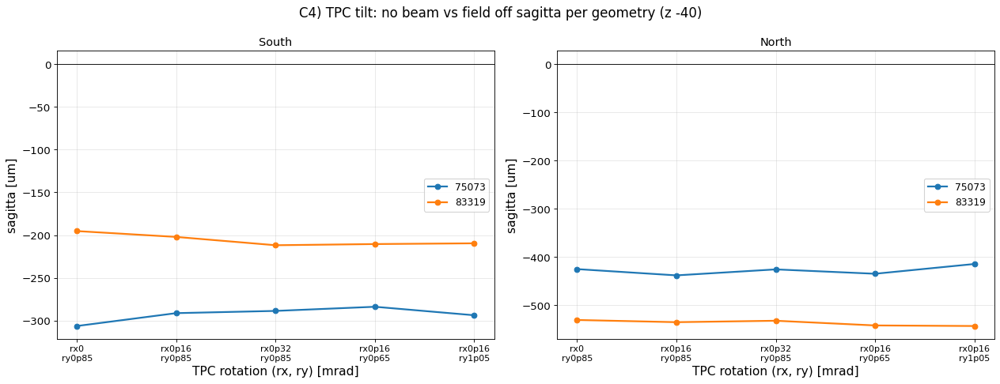

In [16]:
show(b.c_tilt(), b.c_tilt_sag())

## Summary
- **Map (space charge only):** α 1.6 is clearly best. α 1.8 is in between, and α 2.0 fails at high lumi. The inner kink
  (r0 22.75 → 25 cm, width 2 → 4 cm) and the outer fall-off (72 cm) change χ² by only a few percent.
- **keff:** b ≈ 0.59–0.60 for α 1.6. It is the same at low and high luminosity, so keff is linear in the GEM current.
  North needs about 7 % less than South (75073; more with 83319).
- **Static:** with no beam, the static model leaves a sagitta vs field off of about −290 µm South and −430 µm North. It
  is nearly independent of z. Raising the IFC makes it more negative (−3.1 µm/V), so it is removed by **lowering**
  the IFC: about −95 V South / −140 V North (75073), −65 V / −170 V (83319), relative to the nominal (C1). The tilt first
  harmonic is smallest near rot_x 0.32 (C4).
- **Next:**
  1. IFC / OFC fine scan around those offsets, plus a tilt scan around rot_x 0.3.
  2. Module gains vs no beam with α 1.6.
  3. Track test with α 1.6, b 0.6, and the new static model.